# RionSIS: single-injection analysis → RionDS inputs (any isomer, any setting)

One notebook for every data set. Choose `DATASET` in the settings cell and run all cells in order.

**Method** (the same for every setting)
1. STFT with window = time bin (no overlap), band power of the isomer minus a far background band, noise normalised.
2. Bad and noisy injections excluded everywhere.
3. **A1**: raw mixture EM of the per-bin power (ladder-free; negative-binomial ion number with free width r, which
   contains Poisson as r → ∞, so overdispersed data such as 98Mo are treated too). Its bias is removed with the
   **recovery test**: the experiment is simulated with known A1 and the same estimator is applied; A1 = the true value
   that reproduces the real result. (Step median / slope of an integer staircase are NOT used: with a ladder they
   follow the ladder and do not measure A1 at low μ.)
4. **σ0, k**: plateau noise of the staircase fit with the final A1 (quadrature model).
5. Exponential fit of the summed curve with noise-model error bars (+ injection bootstrap, cross-check).
6. **μ, I0**: power of the single injections at early and late times. **σ0 from the tail** of the summed curve (if the
   noise is not white). **Fit start**: split-half test.
7. **Check**: simulated (RionDS model) vs real summed curve and fit error. Then the RionDS `.toml` is written.

Only τ is taken from the exponential fit; everything else comes from the single injections.

In [11]:
# === 0. SETTINGS: choose the data set; everything else below is generic ===
DATASET = "ge_short"          # <<< "ge_long" | "ge_short" | "mo98"

RIONDS_DIR = "/home/carlo/Desktop/PhD/coding/git/RionDS"
SETTINGS = {
    "ge_long": dict(
        DATA_FILE="/home/carlo/Desktop/PhD/coding/results/Ge/files/Corrected data/Long_Setting/72Ge_corr_longset_singlefiles.npy",
        NPERSEG=451,                       # window = bin = 9.236 ms
        T_CUT_MS=0,                        # bins cut at the start of the record [ms]
        BAND_E=(-2760.61, -1570.34),       # isomer band [Hz], relative to the ground state (11 bins)
        BG_BANDS=[(-5600, -3700)],         # flat far background [Hz], relative to the ground state
        HAND_RANGES=((2444, 2458),),       # bad injections (inclusive index ranges)
        TAU_GUESS=0.05,                    # [s] start value of the fits
        A1_TRUE_LIST=None, N_REP=4, N_REC_FILES=None,   # recovery test (None: factors x real EM; all injections)
        USE_EM=True, EM_NB=False,          # Poisson EM (the width r is not separable from ΔI at ~1 ion/injection)
        EM_FILES=None,                     # EM on all injections (μ ≈ 1.5: small memory, less scatter)
        TAIL_S=0.30, LATE_TAU=6.0,         # tail for σ0 [s]; late window for I0 [τ]
        SIGMA0_SOURCE="plateau", FIT_T_START="auto",
        TAG="72ge_long"),
    "ge_short": dict(
        DATA_FILE="/home/carlo/Desktop/PhD/coding/results/Ge/files/Corrected data/Short_Setting/72Ge_corrected-singleions.npy",
        NPERSEG=451, T_CUT_MS=0,
        BAND_E=(-2761.13, -1461.87), BG_BANDS=[(-5600, -3700)], HAND_RANGES=(),
        TAU_GUESS=0.05,
        A1_TRUE_LIST=None, N_REP=30, N_REC_FILES=None,
        USE_EM=True, EM_NB=False, EM_FILES=None, TAIL_S=0.30, LATE_TAU=6.0,
        SIGMA0_SOURCE="plateau", FIT_T_START="auto",
        TAG="72ge_short"),
    "mo98": dict(
        DATA_FILE="/home/carlo/Desktop/PhD/coding/results/Mo/files/rionsis/rionsis_iq_RSA01-2024.05.15.18.30.07.843_RSA01-2024.05.16.09.40.37.773.npy",
        NPERSEG=161,                       # window = bin = 10.02 ms
        T_CUT_MS=35,
        BAND_E=(-2500, -1000), BG_BANDS=[(3500, 5000), (-6000, -4500)],
        HAND_RANGES=((930, 1043), (4243, 4243), (4269, 4269), (7350, 7530), (7644, 10**9)) + (
            (0, 16), (31, 91), (104, 106), (173, 181), (189, 206), (222, 249), (258, 258), (294, 296), (302, 307),
            (322, 342), (349, 360), (367, 405), (1028, 1045), (1058, 1058), (1081, 1081), (1112, 1112), (1152, 1152),
            (1169, 1169), (1300, 1300), (1318, 1318), (1561, 1561), (1601, 1601), (1613, 1613), (1670, 1670),
            (1691, 1691), (1703, 1703), (2372, 2372), (2438, 2438), (2704, 2704), (3718, 3718), (3854, 3854),
            (4654, 4654), (4799, 4799), (4825, 4825), (4836, 4836), (4861, 4863), (4901, 4901), (4976, 4976),
            (5011, 5011), (5037, 5037), (5350, 5350), (5409, 5420), (5579, 5580), (5939, 5939), (6005, 6005),
            (6021, 6021), (6189, 6189), (6293, 6293), (6723, 6723), (7316, 7316), (7492, 7492), (7566, 7567),
            (7863, 7869), (7874, 7877), (7885, 8121), (8126, 8258)),   # hand-made + automatic (ground-state power)
        TAU_GUESS=0.27,
        A1_TRUE_LIST=None, N_REP=3, N_REC_FILES=2000,   # ~5 min per EM at μ≈20: ~1 h in total
        USE_EM=True, EM_NB=True,           # ion number overdispersed: negative-binomial EM (width r fitted)
        TAIL_S=0.60, LATE_TAU=4.0,
        SIGMA0_SOURCE="tail", FIT_T_START=0.10,
        TAG="98mo"),
}
COMMON = dict(
    NOISY_FACTOR=3.0, NOISY_BINS=30,      # noisy injections: late std > factor x median
    REF_SIGMA=0.66, NOISE_BINS=15,        # noise normalisation
    PENALTY_FACTOR=0.30, NMAX_CAP=80,     # staircase fit
    NOISE_MINLEN=5, NOISE_MAX_N=6,        # plateau noise
    STEP_MIN_LEN=5, STEP_MAX_N=6,         # step median / slope estimators
    LADDER="auto",                        # ladder for the optional step/slope estimators ("auto" or a number)
    A1_ESTIMATOR="em",                    # primary estimator of the recovery test
    REC_ESTIMATORS=("em",),               # estimators run in the recovery test ("em", "step", "slope"; step/slope are slow)
    EM_FILES=1000,                        # injections used by the EM (memory), same number for real and simulated data
    A1_TRUE_FACTORS=(0.7, 0.85, 1.0, 1.15),   # recovery-test values = factors x real EM (if A1_TRUE_LIST is None)
    B_BOOT=300,                           # injection bootstrap of the real fit
    N_MU_BINS=5, N_CHECK=100, W_TEST=20,  # section 7
    N_DECAY_STEPS=1, N_TRIALS=1000, SEED=1,
    ION_DIST="auto",                      # "auto": negative binomial if the first-bin test prefers it, else Poisson | "poisson"
    GAMMA=1.3957,                         # Lorentz factor lab -> rest frame
)
globals().update(COMMON); globals().update(SETTINGS[DATASET])
REC_ESTIMATORS = tuple(dict.fromkeys(tuple(REC_ESTIMATORS) + (A1_ESTIMATOR,)))   # the primary estimator always runs
RIONDS_TOML = f"{RIONDS_DIR}/simparams_{TAG}.toml"
EXP_FILE    = f"{RIONDS_DIR}/exp_{TAG}.npz"         # real summed curve, overlaid in the RionDS plots
OUT_PATH, OUT_TAG = f"./out_{TAG}", f"{TAG}_"
CACHE = f"rionsis_cache_{TAG}.pkl"
print(f"DATASET = {DATASET}: {DATA_FILE}")

DATASET = ge_short: /home/carlo/Desktop/PhD/coding/results/Ge/files/Corrected data/Short_Setting/72Ge_corrected-singleions.npy


## 1. Data and spectrogram

In [12]:
# === 1. Data import and STFT (window = bin, no overlap); one global ground-state bin for all files ===
import numpy as np, matplotlib.pyplot as plt, os, pickle, time
from rionsis.io import load_iq_dataset
from rionsis.levels import compute_power_spectrogram

dataset = load_iq_dataset(DATA_FILE)
fs, NF = dataset.fs, dataset.n_files
spectrogram = compute_power_spectrogram(dataset.iq, fs, dt_bin=NPERSEG / fs, nperseg=NPERSEG)
g_vals, g_cnt = np.unique(spectrogram.gbin, return_counts=True)
G_BIN = int(g_vals[np.argmax(g_cnt)])
for i in np.flatnonzero(spectrogram.gbin != G_BIN):          # undo the per-file centering
    spectrogram.power[i] = np.roll(spectrogram.power[i], int(spectrogram.gbin[i]) - G_BIN, axis=0)
i0 = int(round(T_CUT_MS / 1e3 / spectrogram.dt))
power, times = spectrogram.power[:, :, i0:], spectrogram.times[i0:]
print(f"{NF} files, fs = {fs:.3f} Hz | window = bin = {spectrogram.dt*1e3:.3f} ms, df = {spectrogram.df:.1f} Hz | "
      f"cut {i0} bins -> first bin at {times[0]*1e3:.1f} ms, {power.shape[2]} bins")

102 files, fs = 48828.125 Hz | window = bin = 9.236 ms, df = 108.3 Hz | cut 0 bins -> first bin at 4.6 ms, 108 bins


## 2. Band signal, normalisation, bad injections

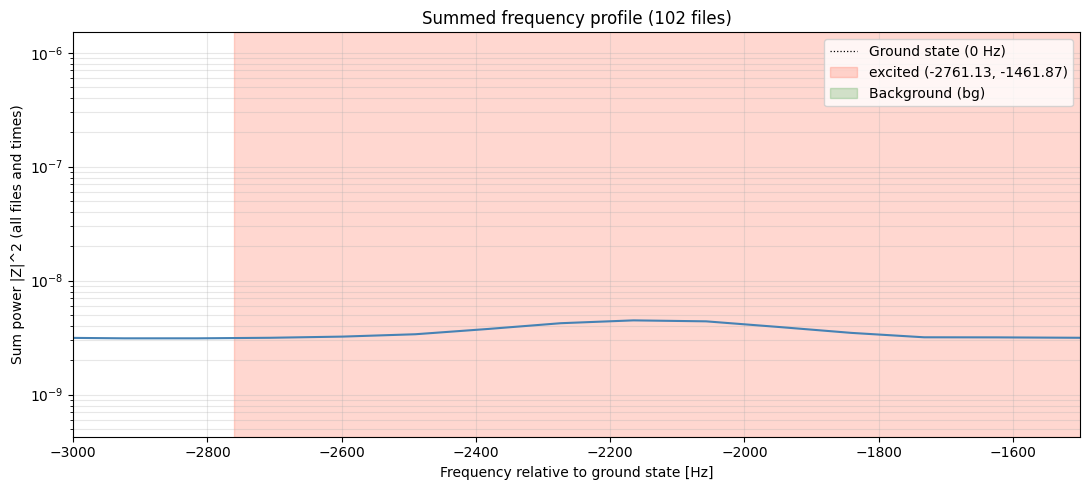

band (-2761.13, -1461.87) Hz -> 12 bins | ground lag-1 = -0.120
bad: 0 by hand, 0 noisy -> 102 good injections


In [13]:
# === 2. Isomer band minus far background, noise normalisation, bad and noisy injections ===
from rionsis.levels import integrate_bands, normalize_ground_noise
from rionsis.plotting import plot_frequency_bands

fig = plot_frequency_bands(spectrogram.frequency, power, BAND_E, BG_BANDS, n_files=NF); plt.show()
band = integrate_bands(power, spectrogram.frequency, BAND_E, BG_BANDS)
noise_norm = normalize_ground_noise(band.y_files, ref_sigma=REF_SIGMA, noise_bins=NOISE_BINS)
y_files_e, sigma_e, dt_e = noise_norm.y_files, noise_norm.sigma, spectrogram.dt
n_t = y_files_e.shape[1]
t9 = np.arange(n_t) * dt_e                                        # t = 0 at the first analysed bin

_bad = np.zeros(NF, bool)
for lo, hi in HAND_RANGES:
    _bad[lo:min(hi, NF - 1) + 1] = True
_late = np.asarray(y_files_e)[:, -NOISY_BINS:].std(axis=1)
NOISY_FILES = np.flatnonzero((_late > NOISY_FACTOR * np.median(_late[~_bad])) & ~_bad)
_bad[NOISY_FILES] = True
GOOD_IDX = np.flatnonzero(~_bad)
Y9 = np.asarray(y_files_e, float)[GOOD_IDX]                      # good injections x time bins
n_files = len(GOOD_IDX); y9 = Y9.sum(0)
sel = (spectrogram.frequency > BAND_E[0]) & (spectrogram.frequency < BAND_E[1])
print(f"band {BAND_E} Hz -> {sel.sum()} bins | ground lag-1 = {noise_norm.ground_acf1:+.3f}")
print(f"bad: {int(_bad.sum()) - len(NOISY_FILES)} by hand, {len(NOISY_FILES)} noisy -> {n_files} good injections")

## 3. Staircase tools and A1 estimators

In [14]:
# === 3. Staircase fit and A1 estimators (used identically on real and simulated data) ===
from rionsis.levels import StaircaseFitConfig, default_change_penalty, fit_integer_dataset
from rionsis.levels.calibration import fit_power_mixture, moment_a1

ground_means = y_files_e[noise_norm.ground_noise_idx, -NOISE_BINS:].mean(axis=1)
ground_level = float(np.median(ground_means))
_gmad = 1.4826 * float(np.median(np.abs(ground_means - ground_level)))
BASELINE_SD = float(np.sqrt(max(_gmad**2 - sigma_e**2 / NOISE_BINS, 1e-6)))

def staircase(y, ladder):
    cfg = StaircaseFitConfig(a1=float(ladder), sigma2_by_n=np.full(NMAX_CAP + 1, sigma_e**2),
                             tau2_by_n=np.full(NMAX_CAP + 1, max(BASELINE_SD, 0.02 * ladder) ** 2),
                             change_penalty=default_change_penalty(y.shape[1], PENALTY_FACTOR),
                             nmax_cap=NMAX_CAP, min_size=1)
    return fit_integer_dataset(y, cfg, file_ids=np.arange(len(y)))

def step_and_slope(fit):
    """Step median of the N -> N+1 plateau steps and slope of plateau level vs N (long plateaus, N <= STEP_MAX_N)."""
    steps = []
    for st, me, le in zip(fit.states, fit.segment_means, fit.segment_lengths):
        st, me, le = np.asarray(st, int), np.asarray(me, float), np.asarray(le, int)
        for k in range(len(st) - 1):
            if abs(st[k + 1] - st[k]) == 1 and min(le[k], le[k + 1]) >= STEP_MIN_LEN and max(st[k], st[k + 1]) <= STEP_MAX_N:
                steps.append((me[k + 1] - me[k]) * np.sign(st[k + 1] - st[k]))
    m = np.concatenate([np.asarray(v, float) for v in fit.segment_means])
    n = np.concatenate([np.asarray(v, float) for v in fit.states])
    L = np.concatenate([np.asarray(v, float) for v in fit.segment_lengths])
    m, n = m[L >= STEP_MIN_LEN], n[L >= STEP_MIN_LEN]
    ns = np.array([k for k in np.unique(n) if (n == k).sum() >= 5 and k <= max(STEP_MAX_N, 10)])
    mu = np.array([m[n == k].mean() for k in ns]); se = np.array([m[n == k].std(ddof=1) / np.sqrt((n == k).sum()) for k in ns])
    slope = np.polyfit(ns, mu, 1, w=1 / se)[0] if len(ns) >= 2 else np.nan
    return (float(np.median(steps)) if steps else np.nan), float(slope)

from rionsis.levels.calibration import _fit_variance_fixed_point, _log_sum_exp, _poisson_exp_decay_mle
from scipy.special import gammaln
from scipy.optimize import minimize_scalar

def _lognb(n, m, r):          # log negative-binomial pmf, mean m, shape r (Poisson for r -> inf)
    return (gammaln(n + r) - gammaln(r) - gammaln(n + 1) + r * np.log(r / (r + m)) + n * np.log(m / (r + m)))

def em_nb(y, n_iter=400, tol=1e-9, fit_r=True):
    """Mixture EM of the per-bin power: x = b + A1 n + N(0, s0² + k² n²), n ~ NegBin(mean μ0 e^(-λt), shape r).
    Like rionsis fit_power_mixture (mode "exp"), with the free width r (binomial decay keeps r unchanged).
    Returns (A1, r)."""
    x = np.asarray(y, float).T
    n_time = x.shape[0]; t_s = np.arange(n_time) * dt_e
    a1 = float(np.clip(moment_a1(y)[0], 0.2, 3.0)); b = 0.0
    m_t = x.mean(1); mu = np.clip((m_t - b) / a1, 1e-6, None)
    n_max = int(mu.max() + 10 * np.sqrt(mu.max() + mu.max() ** 2 / 5)) + 8
    ng = np.arange(n_max + 1.0); n2 = ng * ng
    a, c, r = sigma_e**2, 0.09 * a1**2, (30.0 if fit_r else 1e4)
    prev = np.inf
    for it in range(n_iter):
        s2 = np.maximum(a + c * n2, 1e-12)
        lw = _lognb(ng[None, :], np.maximum(mu, 1e-9)[:, None], r)
        lw -= _log_sum_exp(lw, 1)[:, None]
        z = x[:, :, None] - (b + a1 * ng)
        ll = lw[:, None, :] - 0.5 * z * z / s2 - 0.5 * np.log(2 * np.pi * s2)
        tot = _log_sum_exp(ll, 2); nll = float(-tot.sum())
        R = np.exp(ll - tot[:, :, None])
        n_t = np.einsum("tik,k->t", R, ng)
        mu0, lam = _poisson_exp_decay_mle(n_t, t_s, x.shape[1])
        mu = np.clip(mu0 * np.exp(-lam * t_s), 1e-9, n_max)
        Wn = R.sum(1)                                              # (time, n): posterior counts
        if fit_r:
          r = float(np.exp(minimize_scalar(lambda q: -np.sum(Wn * _lognb(ng[None, :], mu[:, None], np.exp(q))),
                                         bounds=(np.log(0.3), np.log(1e4)), method="bounded").x))
        w = R / s2; sw, swn, swnn = w.sum(), np.einsum("tik,k->", w, ng), np.einsum("tik,k->", w, n2)
        wx = w * x[:, :, None]; swx, swnx = wx.sum(), np.einsum("tik,k->", wx, ng)
        det = sw * swnn - swn**2
        if abs(det) > 1e-12:
            b = (swx * swnn - swn * swnx) / det; a1 = max((sw * swnx - swn * swx) / det, 1e-4)
        res = x[:, :, None] - (b + a1 * ng)
        a, c = _fit_variance_fixed_point(R.sum((0, 1)), (R * res * res).sum((0, 1)), n2, a, c)
        if abs(prev - nll) < tol * max(1.0, abs(nll)):
            break
        prev = nll
    return float(a1), float(r)

def em_raw(y, seed=0):
    if EM_FILES and len(y) > EM_FILES:
        y = y[np.random.default_rng(seed).choice(len(y), EM_FILES, replace=False)]
    return em_nb(y, fit_r=EM_NB)

def a1_procedure(y, ladder):
    """The A1 estimators of REC_ESTIMATORS, identical for the real data and every simulation."""
    out = {}
    if "step" in REC_ESTIMATORS or "slope" in REC_ESTIMATORS:
        out["step"], out["slope"] = step_and_slope(staircase(y, ladder))
    if "em" in REC_ESTIMATORS:
        out["em"], out["r"] = em_raw(y)
    return out

## 4. A1: real data and recovery test

In [15]:
# === 4. A1 from the real data, then the recovery test (cached: delete CACHE to recompute) ===
from rionsis.simulation import build_empirical_noise_library, hann_squared_window_response
from rionsis.simulation.window_response import window_decay_response
from rionsis.levels import calibrate_noise_vs_occupancy

_key = repr((DATASET, NPERSEG, T_CUT_MS, BAND_E, BG_BANDS, n_files, A1_TRUE_LIST, A1_TRUE_FACTORS, N_REP, N_REC_FILES,
             LADDER, REC_ESTIMATORS, EM_FILES, EM_NB, "v8"))
cache = pickle.load(open(CACHE, "rb")) if os.path.isfile(CACHE) else {}
if cache.get("key") != _key:
    cache = {"key": _key}

if "real" not in cache:
    t0_ = time.time()
    L_FIX = (step_and_slope(staircase(Y9, float(np.clip(moment_a1(Y9)[0], 0.2, 3.0))))[0]
             if LADDER == "auto" and ("step" in REC_ESTIMATORS or "slope" in REC_ESTIMATORS)
             else float(np.clip(moment_a1(Y9)[0], 0.2, 3.0)) if LADDER == "auto" else float(LADDER))
    cache["ladder"], cache["real"] = L_FIX, a1_procedure(Y9, L_FIX); pickle.dump(cache, open(CACHE, "wb"))
    print(f"real A1 procedure: {time.time() - t0_:.0f} s")
L_FIX, REAL = cache["ladder"], cache["real"]
print(f"ladder (fixed for real and simulated data) = {L_FIX:.4f}")
print("REAL: " + "  ".join(f"{k} {v:.4f}" for k, v in REAL.items()))

# quantities fixed by the data for the simulations: first-bin power, noise vs power level, τ
_fit0 = staircase(Y9, L_FIX)
_nc0 = calibrate_noise_vs_occupancy(y_files_e, _fit0.segment_lengths, _fit0.states, GOOD_IDX, L_FIX,
                                    min_length=NOISE_MINLEN, max_n=NOISE_MAX_N)
from scipy.optimize import curve_fit
_p = curve_fit(lambda t, A, tau, C: A * np.exp(-t / tau) + C, t9, y9, p0=[y9[0] - y9[-1], TAU_GUESS, y9[-1]], maxfev=20000)[0]
TAU_REC = float(_p[1])
_f1 = TAU_REC / dt_e * (1 - np.exp(-dt_e / TAU_REC))                # bin average of a decaying ion (first bin)
P0 = float(_p[0] / n_files / _f1)                                   # power of the ions at t = 0 (μ·A1)
noise_lib = build_empirical_noise_library(y_files_e, noise_norm.ground_noise_idx, tail_bins=NOISE_BINS)
win_resp = hann_squared_window_response(NPERSEG)
def sigma_for(a1_true):          # noise vs POWER level fixed by the data, in units of a1_true
    return lambda occ: L_FIX * np.asarray(_nc0.sigma_of(a1_true * np.asarray(occ) / L_FIX)) / a1_true

truths = A1_TRUE_LIST or [round(REAL[A1_ESTIMATOR] * f, 3) for f in A1_TRUE_FACTORS]
R_NB = REAL.get("r", 1e4)                   # width of the ion-number distribution, fitted on the real data

def sim_traces(a1_true, N, seed):
    """Like rionsis simulate_decay_traces (window response, empirical noise), with a negative-binomial ion number."""
    rng = np.random.default_rng(seed); rn, rt, rz = rng.spawn(3)
    m0 = P0 / a1_true
    n0 = rn.poisson(rn.gamma(R_NB, m0 / R_NB, N)) if R_NB < 1e3 else rn.poisson(m0, N)
    out = np.empty((N, n_t))
    for i, cnt in enumerate(n0):
        occ = window_decay_response(rt.exponential(TAU_REC, int(cnt)), t9, NPERSEG / fs, win_resp).sum(0) if cnt else np.zeros(n_t)
        out[i] = a1_true * occ + a1_true * np.asarray(sigma_for(a1_true)(occ)) * noise_lib.draw(n_t, rz)
    return out
n_rec = N_REC_FILES or n_files
for a1_true in truths:
    for r in range(N_REP):
        if (a1_true, r) in cache:
            continue
        t0_ = time.time()
        cache[(a1_true, r)] = a1_procedure(sim_traces(a1_true, n_rec, 7 + 1000 * r) + ground_level, L_FIX)
        pickle.dump(cache, open(CACHE, "wb"))
        print(f"A1_true {a1_true:.3f} rep {r}: " + "  ".join(f"{k} {v:.3f}" for k, v in cache[(a1_true, r)].items())
              + f"  ({time.time() - t0_:.0f} s)")

names = [s for s in ("em", "step", "slope") if s in REAL]
rsd = lambda v: 1.4826 * np.median(np.abs(v - np.median(v)))
print("\n" + "=" * 92)
print(f"A1 RECOVERY TEST  (μ·A1 = {P0:.3f} fixed, ion-number width r = {R_NB:.1f}, {n_rec} injections per experiment, "
      f"{N_REP} experiments per value)")
print(f"{'A1 true':>8} | " + " | ".join(f"{s:>16}" for s in names))
for a in truths:
    E = np.array([[cache[(a, r)][s] for s in names] for r in range(N_REP)])
    print(f"{a:8.3f} | " + " | ".join(f"{np.median(E[:, j]):7.3f} ± {rsd(E[:, j]):.3f}" for j in range(len(names))))
print(f"{'REAL':>8} | " + " | ".join(f"{REAL[s]:16.3f}" for s in names))
INFER = {}
for s in names:
    med = np.array([np.median([cache[(a, r)][s] for r in range(N_REP)]) for a in truths])
    sd1 = np.mean([rsd(np.array([cache[(a, r)][s] for r in range(N_REP)])) for a in truths]) * np.sqrt(n_rec / n_files)
    # local inversion: the two simulated values that bracket the real result (the response need not be linear)
    j = int(np.clip(np.searchsorted(med, REAL[s]) if np.all(np.diff(med) > 0) else np.argmin(abs(med - REAL[s])),
                    1, len(truths) - 1))
    b = (med[j] - med[j - 1]) / (truths[j] - truths[j - 1]); c = med[j] - b * truths[j]
    INFER[s] = ((REAL[s] - c) / b if b != 0 else np.nan, sd1 / abs(b) if b != 0 else np.inf, b)
    print(f"{s:>8}: local response {b:.2f}·A1 {c:+.3f} -> A1 = {INFER[s][0]:.4f} ± {INFER[s][1]:.4f}"
          + ("   (blind: response < 0.3)" if abs(b) < 0.3 else "")
          + ("   (outside the simulated range: extend A1_TRUE_LIST)" if not min(truths) <= INFER[s][0] <= max(truths) else ""))
A1, A1_ERR = INFER[A1_ESTIMATOR][0], INFER[A1_ESTIMATOR][1]
_others = [s for s in names if s != A1_ESTIMATOR and abs(INFER[s][2]) >= 0.3]   # blind estimators are not compared
_bad_agree = [s for s in _others if abs(INFER[s][0] - A1) > 2 * np.hypot(INFER[s][1], A1_ERR)]
print("=" * 92)
print(f"A1 = {A1:.4f} ± {A1_ERR:.4f}  ({A1_ESTIMATOR}, bias removed by the recovery test)"
      + (f"   WARNING: {', '.join(_bad_agree)} disagree(s) by > 2σ" if _bad_agree else "   (other estimators agree)"))

real A1 procedure: 5 s
ladder (fixed for real and simulated data) = 1.1025
REAL: em 0.7604  r 10000.0000
A1_true 0.532 rep 0: em 0.449  r 10000.000  (11 s)
A1_true 0.532 rep 1: em 0.477  r 10000.000  (14 s)
A1_true 0.532 rep 2: em 0.542  r 10000.000  (11 s)
A1_true 0.532 rep 3: em 0.475  r 10000.000  (10 s)
A1_true 0.532 rep 4: em 0.351  r 10000.000  (16 s)
A1_true 0.532 rep 5: em 0.391  r 10000.000  (19 s)
A1_true 0.532 rep 6: em 0.702  r 10000.000  (11 s)
A1_true 0.532 rep 7: em 0.358  r 10000.000  (26 s)
A1_true 0.532 rep 8: em 0.405  r 10000.000  (12 s)
A1_true 0.532 rep 9: em 0.346  r 10000.000  (38 s)
A1_true 0.532 rep 10: em 0.555  r 10000.000  (11 s)
A1_true 0.532 rep 11: em 0.593  r 10000.000  (10 s)
A1_true 0.532 rep 12: em 0.525  r 10000.000  (13 s)
A1_true 0.532 rep 13: em 0.460  r 10000.000  (11 s)
A1_true 0.532 rep 14: em 0.333  r 10000.000  (24 s)
A1_true 0.532 rep 15: em 0.551  r 10000.000  (8 s)
A1_true 0.532 rep 16: em 0.421  r 10000.000  (14 s)
A1_true 0.532 rep 17: 

## 5. Noise model σ(N) from the plateaus

σ(N)/A1 = sqrt(0.8340² + (0.5594 N)²) | with the final ladder: step 0.8620, slope 0.8374


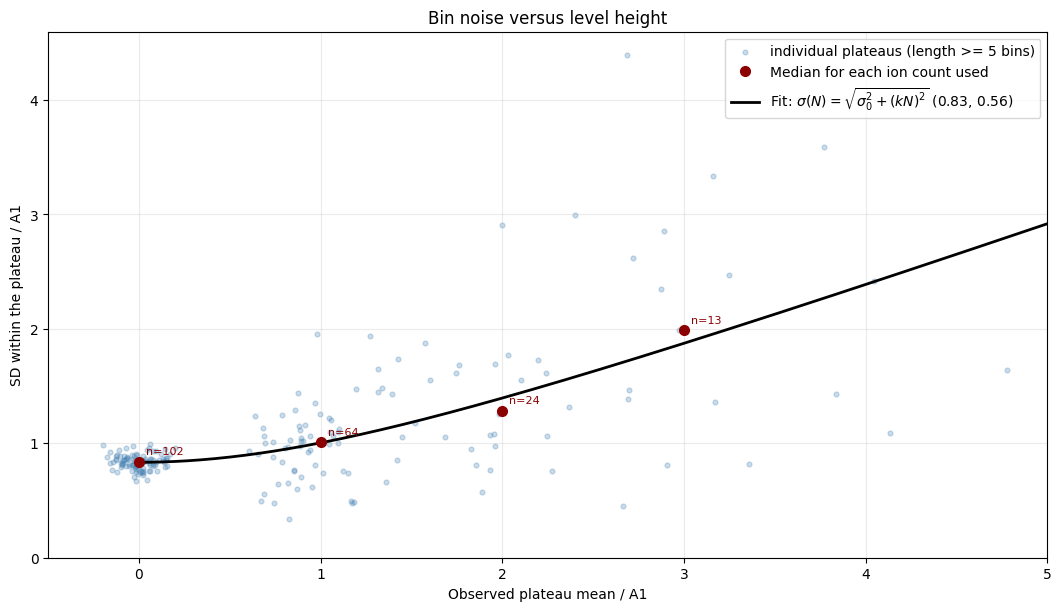

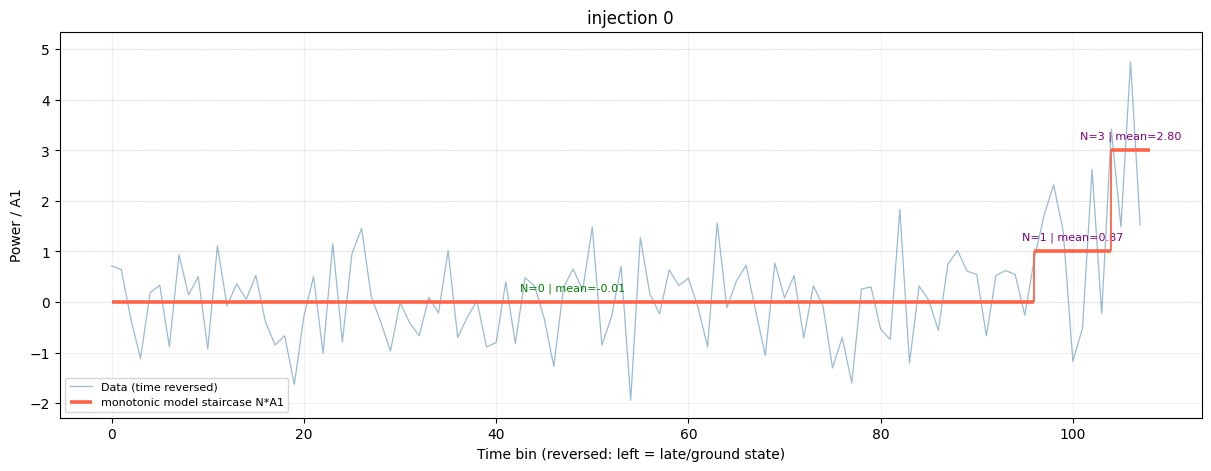

In [16]:
# === 5. Staircase with the final A1, plateau noise σ(N)/A1 = sqrt(σ0² + (k N)²) ===
from rionsis.plotting import plot_noise_vs_occupancy, plot_staircase_fit
real_fit = staircase(Y9, A1)
noise_calibration = calibrate_noise_vs_occupancy(y_files_e, real_fit.segment_lengths, real_fit.states, GOOD_IDX, A1,
                                                 min_length=NOISE_MINLEN, max_n=NOISE_MAX_N)
sigma0, k_noise = float(noise_calibration.sigma0), float(noise_calibration.k)
step_f, slope_f = step_and_slope(real_fit)
print(f"σ(N)/A1 = sqrt({sigma0:.4f}² + ({k_noise:.4f} N)²) | with the final ladder: step {step_f:.4f}, slope {slope_f:.4f}")
plot_noise_vs_occupancy(noise_calibration); plt.show()
plot_staircase_fit(y_files_e[GOOD_IDX[0]], real_fit.fit_levels[0], real_fit.segment_means[0],
                   real_fit.segment_lengths[0], real_fit.states[0], A1, title=f"injection {GOOD_IDX[0]}"); plt.show()

## 6. Exponential fit of the summed curve (error bars from the noise model) and injection bootstrap

102 injections, 108 bins, dt = 9.236 ms
τ_lab = 50.311 ± 1.916 (fit) ± 1.698 (bootstrap) ms | χ²ᵣ 1.21 lag-1 -0.26 | T½ rest 24.986 ms   (no σ: τ_lab 52.472)


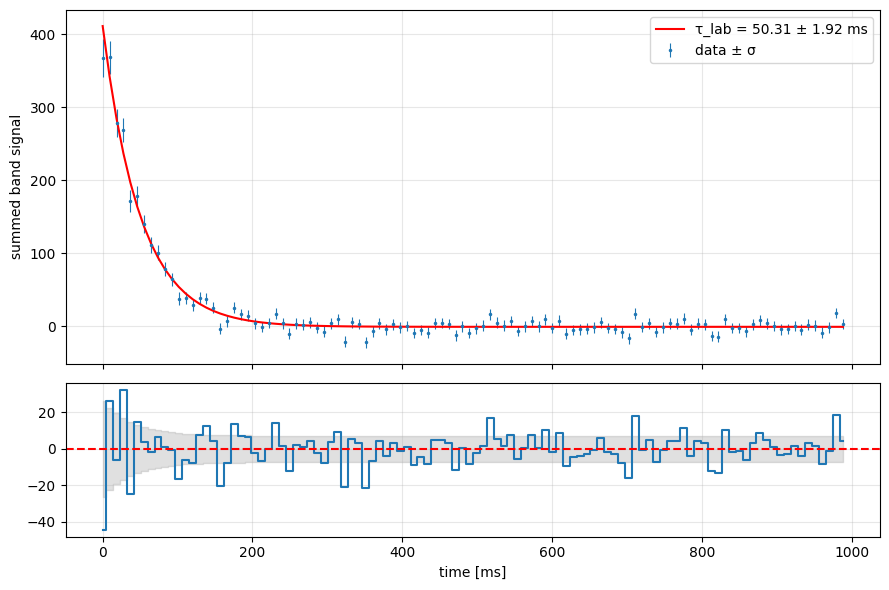

In [17]:
# === 6. Fit A e^(-t/τ) + C with σ_sum(t)² = N·A1²·(σ0² + k²(μ(t) + μ(t)²)), errors × √χ²ᵣ; injection bootstrap ===
def f9(t, A, tau, C):
    return A * np.exp(-t / tau) + C

def fit9(y, s, t0=0.0, p0=None):
    m = t9 >= t0 - 1e-12
    if p0 is None:
        p0 = [y[m][0] - y[-1], TAU_GUESS, y[-1]]
    p, c = curve_fit(f9, t9[m], y[m], p0=p0, sigma=None if s is None else s[m], absolute_sigma=False, maxfev=20000)
    r = y[m] - f9(t9[m], *p)
    return dict(p=p, c=c, tau=p[1], dtau=np.sqrt(c[1, 1]), t=t9[m], y=y[m], res=r, s=None if s is None else s[m],
                lag1=np.corrcoef(r[:-1], r[1:])[0, 1],
                chi2r=np.sum((r / s[m]) ** 2) / (m.sum() - 3) if s is not None else np.nan)

def sigma9(p, s0=None):
    mu_t = p[0] * np.exp(-t9 / p[1]) / (n_files * A1)
    return A1 * np.sqrt(n_files * ((sigma0 if s0 is None else s0) ** 2 + k_noise**2 * (mu_t + mu_t**2)))

fit9_nos = fit9(y9, None)
p_ = fit9_nos["p"]
for _ in range(2):
    s9 = sigma9(p_); p_ = fit9(y9, s9, p0=p_)["p"]
s9 = sigma9(p_)
fit9_main = fit9(y9, s9, p0=p_)
rng9 = np.random.default_rng(0)
_tb = []
for _ in range(B_BOOT):
    try:
        _tb.append(fit9(rng9.multinomial(n_files, np.full(n_files, 1 / n_files)) @ Y9, s9, p0=p_)["tau"])
    except Exception:
        pass
fit9_main["dtau_bs"] = float(np.std(_tb, ddof=1))
hl = np.log(2) / GAMMA * 1e3
r_ = fit9_main
print(f"{n_files} injections, {n_t} bins, dt = {dt_e*1e3:.3f} ms")
print(f"τ_lab = {r_['tau']*1e3:.3f} ± {r_['dtau']*1e3:.3f} (fit) ± {r_['dtau_bs']*1e3:.3f} (bootstrap) ms | χ²ᵣ {r_['chi2r']:.2f} "
      f"lag-1 {r_['lag1']:+.2f} | T½ rest {r_['tau']*hl:.3f} ms   (no σ: τ_lab {fit9_nos['tau']*1e3:.3f})")
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw=dict(height_ratios=[3, 1.3]))
ax[0].errorbar(r_["t"] * 1e3, r_["y"], r_["s"], fmt=".", ms=3, lw=.8, label="data ± σ")
ax[0].plot(r_["t"] * 1e3, f9(r_["t"], *r_["p"]), "r-", label=f"τ_lab = {r_['tau']*1e3:.2f} ± {r_['dtau']*1e3:.2f} ms")
ax[0].legend(); ax[0].grid(alpha=.3); ax[0].set_ylabel("summed band signal")
ax[1].step(r_["t"] * 1e3, r_["res"], where="mid"); ax[1].fill_between(r_["t"] * 1e3, -r_["s"], r_["s"], step="mid", alpha=.3, color="0.6")
ax[1].axhline(0, color="r", ls="--"); ax[1].set_xlabel("time [ms]"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. RionDS inputs from the single injections, check against the real curve, `.toml`

σ0: plateaus 0.8340 A1, tail 0.8591 A1 (ratio 1.03) -> using plateau
  fit start    0.0 ms: split-half correlation +0.21 (threshold +0.61)
INPUTS  A1 = 0.8580 ± 0.2187   σ0 = 0.8340 A1 (plateau)   k = 0.5594 A1   I0 = -0.00772   μ = 5.0939 ± 1.3199 (from 0 ms)
        ion number: Poisson  (2ΔlogL NB vs Poisson = -0.0)
        τ = 50.259 ms (fit from 0.0 ms)   [fit amplitude A/(N·A1·f1) = 5.1525]
CHECK   curve χ² (fit range) = 120.7 / 108 bins (≈ 108 ± 15); all bins 120.7 / 108   A real/sim +2.0% (fit from 0 ms)   C real -0.80 sim -0.75
        σ_fit real 1.961 ms  sim 1.844 ± 0.168 ms  pull +0.7  (|pull| < 2: experiment correctly simulated)   χ²ᵣ real 1.20 sim 1.01
        noise real/sim (half differences): 0-323 ms 0.99 | 333-656 ms 1.02 | 665-988 ms 1.04   (≈ 1: noise model right)


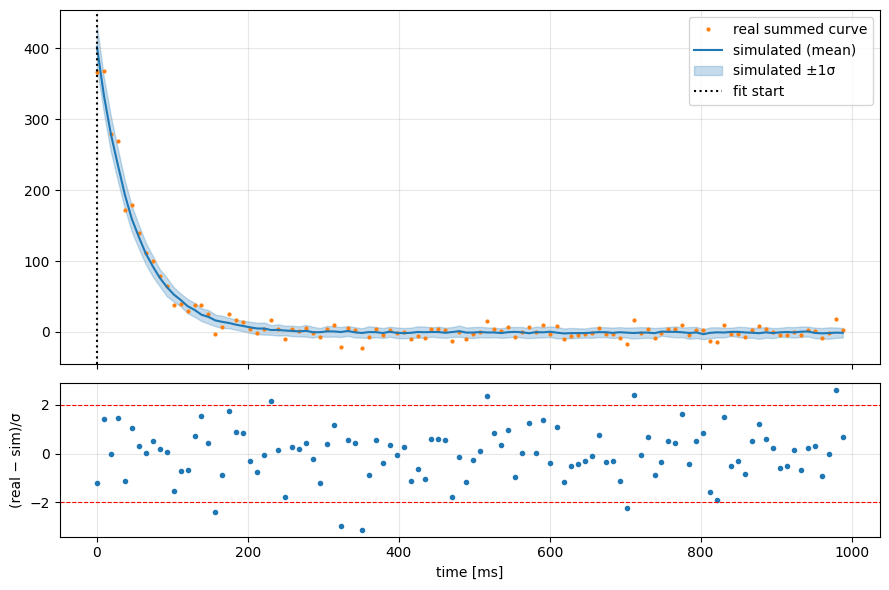

written: /home/carlo/Desktop/PhD/coding/git/RionDS/simparams_72ge_short.toml  and  /home/carlo/Desktop/PhD/coding/git/RionDS/exp_72ge_short.npz


In [18]:
# === 7. RionDS inputs (single injections), σ0 from the tail, fit start, check, toml ===
tau_s = float(fit9_main["tau"]); dt_s, N_inj, nb = float(dt_e), int(n_files), int(n_t)
f1 = tau_s / dt_s * (1 - np.exp(-dt_s / tau_s)) if N_DECAY_STEPS == 1 else 1.0
t_mu = float(FIT_T_START) if FIT_T_START != "auto" else 0.0     # μ is measured where the fit starts
early = (t9 >= t_mu - 1e-9) & (t9 < t_mu + (N_MU_BINS - 0.5) * dt_s); late = t9 > LATE_TAU * tau_s
def mu_I0(Y):            # μ (ions at the start of the first bin) and I0 from the early and late power
    Pm = Y.mean(0)
    M = np.array([[1.0, A1 * f1 * np.mean(np.exp(-t9[w] / tau_s))] for w in (early, late)])
    return map(float, np.linalg.solve(M, [Pm[early].mean(), Pm[late].mean()]))
I0_st, mu_st = mu_I0(Y9)
k_st = k_noise

from scipy.stats import poisson as _po, nbinom as _nbd, norm as _no
from scipy.optimize import minimize as _mini
def ion_width():
    """Width r of the ion-number distribution at the start of the fit (negative binomial vs Poisson, each convolved
    with the plateau noise of one bin). Returns (r or None for Poisson, 2ΔlogL)."""
    j0 = int(np.argmax(t9 >= t_mu - 1e-9)); z = (Y9[:, j0] - I0_st) / A1
    m = mu_st * np.exp(-t9[j0] / tau_s)
    nn = np.arange(int(m + 10 * np.sqrt(m + m * m / 3) + 10)); sg = np.sqrt(sigma0**2 + (k_noise * nn) ** 2)
    L = lambda pn: np.log(np.clip((pn[None, :] * _no.pdf(z[:, None], f1 * nn[None, :], sg[None, :])).sum(1), 1e-300, None)).sum()
    lp = L(_po.pmf(nn, m))
    q = _mini(lambda q: -L(_nbd.pmf(nn, np.exp(q[0]), np.exp(q[0]) / (np.exp(q[0]) + m))), [np.log(10.0)],
              bounds=[(np.log(0.3), np.log(1e4))])
    d2 = float(2 * (-q.fun - lp))
    return (float(np.exp(q.x[0])) if (ION_DIST == "auto" and d2 > 3.84) else None), d2
R7, D2_7 = ion_width()

def sim_sum(rng, s0, N=None):
    """One simulated experiment, exactly the RionDS model (Poisson ions, intermediate frame, quadrature noise)."""
    N = N_inj if N is None else N
    n0 = rng.poisson(rng.gamma(R7, mu_st / R7, N)) if R7 else rng.poisson(mu_st, N)
    td = rng.exponential(tau_s, n0.sum()); own = np.repeat(np.arange(N), n0)
    j = np.minimum((td // dt_s).astype(int), nb)
    cnt = np.zeros((N, nb + 1)); np.add.at(cnt, (own, j), 1)
    n_start = n0[:, None] - np.cumsum(cnt, 1)[:, :nb] + cnt[:, :nb]
    occ = n_start - cnt[:, :nb]
    if N_DECAY_STEPS == 1:
        part = np.zeros((N, nb + 1)); np.add.at(part, (own, j), td / dt_s - j); occ = occ + part[:, :nb]
    return (I0_st + A1 * occ + A1 * np.sqrt(s0**2 + (k_st * n_start) ** 2) * rng.standard_normal((N, nb))).sum(0)

def s_rd(s0):            # RionDS error bars
    mu_t = mu_st * np.exp(-t9 / tau_s)
    return A1 * np.sqrt(N_inj * (s0**2 + k_st**2 * (mu_t + mu_t**2 * (1 + (1 / R7 if R7 else 0)))))

# σ0 from the tail: simulated tail residual variance = real one (k unchanged)
rng_c = np.random.default_rng(SEED)
tail = lambda y, s0: np.mean(fit9(y, s_rd(s0), p0=fit9_main["p"])["res"][t9 >= TAIL_S] ** 2)
v_sim = np.mean([tail(sim_sum(rng_c, sigma0), sigma0) for _ in range(20)])
sigma0_tail = float(np.sqrt(max(sigma0**2 + (tail(y9, sigma0) - v_sim) / (N_inj * A1**2), 0)))
s0_st = sigma0 if SIGMA0_SOURCE == "plateau" else sigma0_tail
print(f"σ0: plateaus {sigma0:.4f} A1, tail {sigma0_tail:.4f} A1 (ratio {sigma0_tail/sigma0:.2f}) -> using {SIGMA0_SOURCE}")

# fit start: split-half test (shape common to all injections; σ_fit does not enter)
def split_corr(h1, h2, t0):
    m = t9 >= t0 - 1e-12; w = m & (t9 < t9[m][0] + W_TEST * dt_s)
    r = [h - f9(t9, *fit9(h, s_rd(s0_st) / np.sqrt(2), t0, p0=fit9_main["p"] / [2, 1, 2])["p"]) for h in (h1, h2)]
    return np.corrcoef(r[0][w], r[1][w])[0, 1]
null = [split_corr(sim_sum(rng_c, s0_st, N_inj // 2), sim_sum(rng_c, s0_st, N_inj // 2), 0.0) for _ in range(30)]
thr = float(np.mean(null) + 2 * np.std(null, ddof=1))
rng_h = np.random.default_rng(3)
def real_split(t0):
    return np.mean([split_corr(*(lambda p: (Y9[p[::2]].sum(0), Y9[p[1::2]].sum(0)))(rng_h.permutation(N_inj)), t0)
                    for _ in range(10)])
if FIT_T_START == "auto":
    t_fit = None
    for kb in range(0, int(0.4 * nb), 5):
        c_ = real_split(t9[kb]); print(f"  fit start {t9[kb]*1e3:6.1f} ms: split-half correlation {c_:+.2f} (threshold {thr:+.2f})")
        if c_ < thr:
            t_fit = float(t9[kb]); break
    if t_fit is None:
        t_fit = float(t9[kb]); print("  WARNING: shape common to all injections in the whole first 40 % of the record")
else:
    t_fit = float(FIT_T_START)
    print(f"  fit start set by hand: {t_fit*1e3:.1f} ms (split-half correlation {real_split(t_fit):+.2f}, threshold {thr:+.2f})")
if abs(t_fit - t_mu) > 1e-9:                                       # auto start > 0: μ, I0 again from the fit start
    t_mu = t_fit
    early = (t9 >= t_mu - 1e-9) & (t9 < t_mu + (N_MU_BINS - 0.5) * dt_s)
    I0_st, mu_st = mu_I0(Y9)
    R7, D2_7 = ion_width()

# check: N_CHECK simulated experiments vs the real data, same fit
S = np.array([sim_sum(rng_c, s0_st) for _ in range(N_CHECK)])
fits = [fit9(y, s_rd(s0_st), t_fit, p0=fit9_main["p"]) for y in S]
real = fit9(y9, s_rd(s0_st), t_fit, p0=fit9_main["p"])
m_sim, sd_sim = S.mean(0), S.std(0, ddof=1)
pull = (y9 - m_sim) / sd_sim
mf = t9 >= t_fit - 1e-9                                            # bins of the fit
dts = np.array([f["dtau"] for f in fits])
A_sim, C_sim = np.mean([f["p"][0] for f in fits]), np.mean([f["p"][2] for f in fits])
# uncertainty of μ: injections resampled (stat) and A1
rng_mu = np.random.default_rng(1)
mu_bs = [list(mu_I0(Y9[rng_mu.integers(0, N_inj, N_inj)]))[1] for _ in range(200)]
mu_err = float(np.hypot(np.std(mu_bs, ddof=1), mu_st * A1_ERR / A1))

print("=" * 92)
print(f"INPUTS  A1 = {A1:.4f} ± {A1_ERR:.4f}   σ0 = {s0_st:.4f} A1 ({SIGMA0_SOURCE})   k = {k_st:.4f} A1   "
      f"I0 = {I0_st:+.5f}   μ = {mu_st:.4f} ± {mu_err:.4f} (from {t_mu*1e3:.0f} ms)")
print(f"        ion number: {'negative binomial, r = %.1f' % R7 if R7 else 'Poisson'}  (2ΔlogL NB vs Poisson = {D2_7:.1f})")
print(f"        τ = {real['tau']*1e3:.3f} ms (fit from {t_fit*1e3:.1f} ms)   [fit amplitude A/(N·A1·f1) = "
      f"{fit9_main['p'][0]/(N_inj*A1*f1):.4f}]")
print(f"CHECK   curve χ² (fit range) = {np.sum(pull[mf]**2):.1f} / {mf.sum()} bins (≈ {mf.sum()} ± {np.sqrt(2*mf.sum()):.0f}); "
      f"all bins {np.sum(pull**2):.1f} / {nb}   A real/sim {real['p'][0]/A_sim - 1:+.1%} "
      f"(fit from {t_fit*1e3:.0f} ms)   C real {real['p'][2]:.2f} sim {C_sim:.2f}")
print(f"        σ_fit real {real['dtau']*1e3:.3f} ms  sim {dts.mean()*1e3:.3f} ± {dts.std(ddof=1)*1e3:.3f} ms  "
      f"pull {(real['dtau']-dts.mean())/dts.std(ddof=1):+.1f}  (|pull| < 2: experiment correctly simulated)   "
      f"χ²ᵣ real {real['chi2r']:.2f} sim {np.mean([f['chi2r'] for f in fits]):.2f}")
# noise only: difference of two random halves (any shape common to all injections cancels)
rng_d = np.random.default_rng(5)
def _hd(Y):
    p = rng_d.permutation(len(Y)); return Y[p[::2]].sum(0) - Y[p[1::2]].sum(0)
_rd = np.array([_hd(Y9) for _ in range(20)])
_sd = np.array([sim_sum(rng_c, s0_st, N_inj // 2) - sim_sum(rng_c, s0_st, N_inj // 2) for _ in range(40)])
_w = np.array_split(np.flatnonzero(mf), 3)
print("        noise real/sim (half differences): " + " | ".join(
      f"{t9[w[0]]*1e3:.0f}-{t9[w[-1]]*1e3:.0f} ms {_rd[:, w].std() / _sd[:, w].std():.2f}" for w in _w)
      + "   (≈ 1: noise model right)")
print("=" * 92)
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw=dict(height_ratios=[3, 1.3]))
ax[0].plot(t9 * 1e3, y9, ".", ms=4, color="C1", label="real summed curve")
ax[0].plot(t9 * 1e3, m_sim, color="C0", label="simulated (mean)")
ax[0].fill_between(t9 * 1e3, m_sim - sd_sim, m_sim + sd_sim, color="C0", alpha=.25, label="simulated ±1σ")
ax[0].axvline(t_fit * 1e3, color="k", ls=":", label="fit start"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(t9 * 1e3, pull, "o", ms=3); [ax[1].axhline(v, color="r", ls="--", lw=.8) for v in (-2, 2)]
ax[1].set_ylabel("(real − sim)/σ"); ax[1].set_xlabel("time [ms]"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

np.savez(EXP_FILE, t=t9, y=y9, sigma=s_rd(s0_st))
toml_txt = f"""# RionDS input, {DATASET}. Written by the RionSIS notebook ({N_inj} injections): rerun it instead of editing.
[params]
# exponential fit (with σ) of the real summed curve
tau_seed        = {real['tau']:.6e}   # [s] τ_lab (fit from fit_t_start)
fit_t_start     = {t_fit:.6e}   # [s] first time of the fit (first bin = 0)
sigma_fit_real  = {real['dtau']:.6e}   # [s] fit error of τ_lab of the real data (for ρ and σ_corr)
exp_data_file   = "{EXP_FILE}"   # real summed curve, overlaid in the plots
# single injections   (A1 = {A1:.4f} ± {A1_ERR:.4f}, σ0 = {s0_st:.4f} A1 ({SIGMA0_SOURCE}), k = {k_st:.4f} A1)
mean_ion_number = {mu_st:.6f}       # μ (± {mu_err:.4f})
mean_bkgnd      = {I0_st:.6e}   # I0
mean_ion        = {I0_st + A1:.6e}   # I1 = I0 + A1
stdv_bkgnd      = {s0_st * A1:.6e}   # σ(I0) = σ0·A1
stdv_ion        = {k_st * A1:.6e}   # σ(I1) = k·A1
ion_number_r    = {R7 if R7 else 0:.4g}   # width of the ion-number distribution (negative binomial); 0 = Poisson
# data
timestep        = {dt_s:.6e}   # [s] time bin
n_sim_steps     = {nb}            # time bins
n_sim           = {N_inj}           # injections summed (after cuts)
# simulation
n_decay_steps   = {N_DECAY_STEPS}              # intermediate frame
empty_shots_probability = 0.0    # extra empty injections (0 = none)
n_trials        = {N_TRIALS}
seed            = {SEED}

[settings]
output_path = "{OUT_PATH}"
output_tag  = "{OUT_TAG}"
"""
open(RIONDS_TOML, "w").write(toml_txt)
print(f"written: {RIONDS_TOML}  and  {EXP_FILE}")

## Appendix (optional): is the ion number Poisson?

Poisson μ = 4.393 | negative binomial μ = 4.393, r = 4457.8 | 2ΔlogL = -0.0 (> 3.8: overdispersion at 95 %)


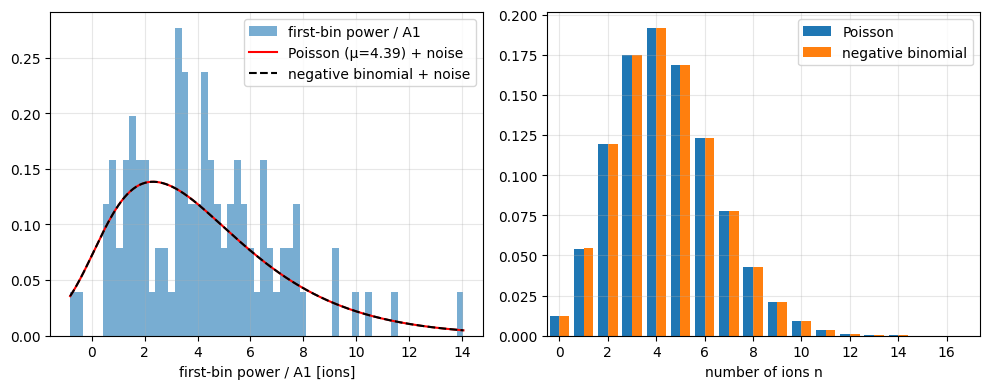

In [19]:
# === A. First-bin ions: Poisson vs negative binomial (each convolved with the noise model) ===
from scipy.stats import poisson, nbinom, norm
from scipy.optimize import minimize
z = (Y9[:, 0] - I0_st) / A1                       # first-bin power in units of A1
nn = np.arange(int(mu_st + 8 * np.sqrt(mu_st) + 10))
sig_n = np.sqrt(s0_st**2 + (k_st * nn) ** 2)
def like(pn):                                      # P(z) = Σ_n P(n) N(z; f1·n, σ(n))
    return np.clip((pn[None, :] * norm.pdf(z[:, None], f1 * nn[None, :], sig_n[None, :])).sum(1), 1e-300, None)
nll_p = lambda q: -np.log(like(poisson.pmf(nn, q[0]))).sum()
nll_nb = lambda q: -np.log(like(nbinom.pmf(nn, q[1], q[1] / (q[1] + q[0])))).sum()
rp = minimize(nll_p, [mu_st], bounds=[(0.01, None)])
rn = minimize(nll_nb, [mu_st, 20.0], bounds=[(0.01, None), (0.05, 1e4)])
print(f"Poisson μ = {rp.x[0]:.3f} | negative binomial μ = {rn.x[0]:.3f}, r = {rn.x[1]:.1f} | "
      f"2ΔlogL = {2*(rp.fun - rn.fun):.1f} (> 3.8: overdispersion at 95 %)")
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
xx = np.linspace(z.min(), z.max(), 400)
ax[0].hist(z, bins=60, density=True, alpha=.6, label="first-bin power / A1")
for pn, lab, ls in ((poisson.pmf(nn, rp.x[0]), f"Poisson (μ={rp.x[0]:.2f}) + noise", "r-"),
                    (nbinom.pmf(nn, rn.x[1], rn.x[1] / (rn.x[1] + rn.x[0])), "negative binomial + noise", "k--")):
    ax[0].plot(xx, (pn[None, :] * norm.pdf(xx[:, None], f1 * nn[None, :], sig_n[None, :])).sum(1), ls, label=lab)
ax[0].set_xlabel("first-bin power / A1 [ions]"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].bar(nn - .2, poisson.pmf(nn, rp.x[0]), .4, label="Poisson")
ax[1].bar(nn + .2, nbinom.pmf(nn, rn.x[1], rn.x[1] / (rn.x[1] + rn.x[0])), .4, label="negative binomial")
ax[1].set_xlim(-.5, mu_st + 5 * np.sqrt(mu_st) + 1); ax[1].set_xlabel("number of ions n"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Appendix B (optional): intensity histogram used by the EM

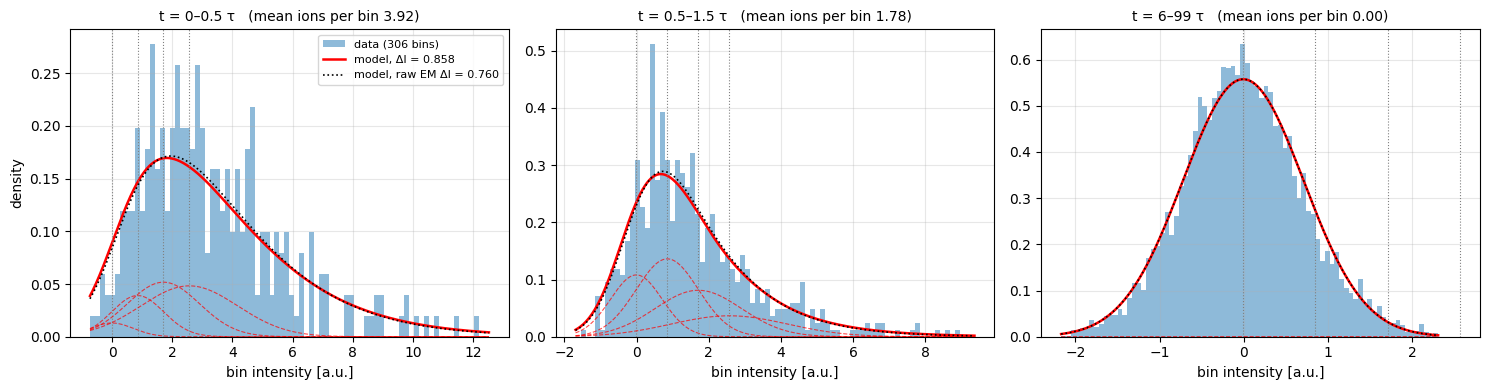

dotted grey lines: I0 + N·ΔI (N = 0, 1, 2, ...); dashed red: the single-N components of the model


In [20]:
# === Appendix B: intensity histogram used by the mixture EM (run after section 7) ===
# Every time bin of every good injection is one entry (no staircase fit). The model is the EM mixture:
#   P(x) = Σ_N P(N; μ(t)) · Gauss(x; I0 + N·ΔI, σ(N)),   μ(t) = f1·μ·e^(-t/τ),   σ(N) = ΔI·sqrt(σ0² + (kN)²)
# shown in three time windows (the shape changes as the ions decay), with the single-N components dashed.
import numpy as np, matplotlib.pyplot as plt
from scipy.stats import norm, poisson, nbinom

WINDOWS_TAU = [(0, 0.5), (0.5, 1.5), (6, 99)]          # time windows in units of τ
N_SHOW = 4                                             # single-N components drawn (N = 0 .. N_SHOW-1)
DI_RAW = REAL.get("em", np.nan)                        # raw EM value (before the recovery correction)

def model(x, t_sel, dI):
    """Mixture density averaged over the bins of the window; dI = single-ion step, μ·ΔI kept as measured."""
    mu_t = f1 * (mu_st * A1 / dI) * np.exp(-t_sel / tau_s)            # mean ions per bin, same total intensity
    nn = np.arange(int(mu_t.max() + 8 * np.sqrt(mu_t.max() + 1) + 8))
    sg = A1 * np.sqrt(sigma0**2 + (k_noise * nn * dI / A1) ** 2)        # noise vs intensity fixed by the data
    pn = np.array([(nbinom.pmf(nn, R7, R7 / (R7 + m)) if R7 else poisson.pmf(nn, m)) for m in mu_t]).mean(0)
    comp = pn[None, :] * norm.pdf(x[:, None], I0_st + nn[None, :] * dI, sg[None, :])
    return comp.sum(1), comp

fig, axs = plt.subplots(1, len(WINDOWS_TAU), figsize=(5 * len(WINDOWS_TAU), 4), sharey=False)
for ax, (a, b) in zip(axs, WINDOWS_TAU):
    m = (t9 >= a * tau_s) & (t9 < b * tau_s)
    if not m.any():
        ax.set_visible(False); continue
    x_data = Y9[:, m].ravel()
    lo, hi = np.percentile(x_data, [0.2, 99.8])
    xx = np.linspace(lo, hi, 600)
    ax.hist(x_data, bins=80, range=(lo, hi), density=True, color="C0", alpha=0.5, label=f"data ({x_data.size} bins)")
    tot, comp = model(xx, t9[m], A1)
    ax.plot(xx, tot, "r-", lw=1.8, label=f"model, ΔI = {A1:.3f}")
    for n in range(min(N_SHOW, comp.shape[1])):
        ax.plot(xx, comp[:, n], "r--", lw=0.8, alpha=0.7)
        ax.axvline(I0_st + n * A1, color="0.5", ls=":", lw=0.8)
    if np.isfinite(DI_RAW):
        ax.plot(xx, model(xx, t9[m], DI_RAW)[0], "k:", lw=1.2, label=f"model, raw EM ΔI = {DI_RAW:.3f}")
    ax.set_title(f"t = {a:g}–{b:g} τ   (mean ions per bin {f1*mu_st*np.mean(np.exp(-t9[m]/tau_s)):.2f})", fontsize=10)
    ax.set_xlabel("bin intensity [a.u.]"); ax.grid(alpha=0.3)
axs[0].set_ylabel("density"); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("dotted grey lines: I0 + N·ΔI (N = 0, 1, 2, ...); dashed red: the single-N components of the model")